# WINGBEATS: ResNet-50 + CBAM Training on Modal

This notebook is used to train a ResNet-50 model with CBAM attention on the WINGBEATS dataset. Training runs on an **NVIDIA A100 GPU** through Modal. The local computer is only used to start jobs and view their logs.

The model starts with ImageNet-pretrained weights and is trained to classify six mosquito species. We use the full training dataset, with up to 10 epochs and early stopping.

**Before running:** Use Python 3.11, install `requirements.txt`, and run `python -m modal setup`. Run the notebook cells in order. Modal jobs can cost money, so check the settings before starting.

## 1. Locate the repository

Find the project folder and set it as the working directory.

Only the Modal SDK is needed locally. PyTorch and the other training libraries are installed on Modal, so they are not needed on your computer.

In [1]:
from pathlib import Path
import os
import sys
import json

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "modal_jobs" / "app.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the extracted repository directory.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Repository:", ROOT)
print("Local Python:", sys.version.split()[0], "(Python 3.11 is recommended)")

Repository: /Users/dpizhuk/Desktop/jku/ai_and_vis/mosquito-wingbeat-vis4ai
Local Python: 3.11.15 (Python 3.11 is recommended)


## 2. Optional Kaggle secret

The WINGBEATS dataset can normally be downloaded without a Kaggle token. Leave `KAGGLE_SECRET_NAME = None` if the download works.

If Kaggle requires a login, create a Modal Secret with your `KAGGLE_API_TOKEN` and enter the secret's name here. Do not put the actual token in the notebook.

Restart the notebook kernel if you change this setting after importing the Modal app.

In [2]:
KAGGLE_SECRET_NAME = None  # Example name: "wingbeats-kaggle"
if KAGGLE_SECRET_NAME:
    os.environ["WINGBEAT_KAGGLE_SECRET"] = KAGGLE_SECRET_NAME
else:
    os.environ.pop("WINGBEAT_KAGGLE_SECRET", None)

import modal
from common.config import DataConfig, TrainConfig, fingerprint
from modal_jobs.app import (app, prepare_data, benchmark, train, evaluate,
                            package_run, status, data_volume, run_volume)
from modal_jobs.client import download_volume_file, extract_run_bundle
print("Modal SDK:", modal.__version__)

Modal SDK: 1.6.3


## 3. Training settings and budget

We use `configs/full.json` for training on the full dataset. The file contains the model settings, number of epochs, batch size and budget limits.

Before starting, check your available Modal credits. The budget settings help limit training costs, but they do not cover all possible charges, such as data preparation, storage and other jobs.

Set `ALLOW_BILLED_COMPUTE = True` to allow remote jobs.

In [3]:
ALLOW_BILLED_COMPUTE = True  # Set True only after reviewing the settings.
CONFIG_PATH = ROOT / "configs" / "full.json"
PREPARATION_ID = "wingbeats-v1"
RUN_ID = "r50-cbam-full-001"  # New ID for a different experiment.
RESUME = False                # True only when this run already has last.pt.

DATA_CONFIG = DataConfig.from_dict(json.loads((ROOT / "configs/data.json").read_text())).to_dict()
TRAIN_CONFIG = TrainConfig.load(CONFIG_PATH).to_dict()
config = TrainConfig.from_dict(TRAIN_CONFIG)

print(json.dumps(TRAIN_CONFIG, indent=2))
print(f"Approximate allocated compute rate: ${config.estimated_usd_per_second * 3600:.3f}/hour")
print(f"Effective cumulative training timer: {config.allowed_seconds / 3600:.2f} hours")
print("This is NOT a guarantee that total Modal charges stay within $30.")
(ROOT / "results").mkdir(exist_ok=True)
(ROOT / "results/session.json").write_text(json.dumps({
    "preparation_id": PREPARATION_ID, "run_id": RUN_ID,
    "data_config": DATA_CONFIG, "train_config": TRAIN_CONFIG,
}, indent=2))

{
  "model": {
    "pretrained": true,
    "attention_stages": [
      2,
      3
    ],
    "reduction": 16,
    "spatial_kernel": 7,
    "dropout": 0.2
  },
  "seed": 42,
  "epochs": 10,
  "warmup_epochs": 1,
  "batch_size": 128,
  "num_workers": 4,
  "max_train_samples": null,
  "max_validation_samples": null,
  "head_lr": 0.001,
  "attention_lr": 0.0002,
  "backbone_lr": 3e-05,
  "weight_decay": 0.0001,
  "label_smoothing": 0.05,
  "class_weighting": true,
  "unfreeze_from_stage": 2,
  "freeze_bn_stats": true,
  "patience": 3,
  "min_delta": 0.001,
  "precision": "bf16",
  "gradient_clip": 1.0,
  "augment": true,
  "frequency_mask_bins": 8,
  "time_mask_frames": 8,
  "log_every_steps": 25,
  "checkpoint_every_seconds": 180.0,
  "max_hours": 6,
  "compute_budget_usd": 20,
  "estimated_usd_per_second": 0.00078192,
  "budget_safety_factor": 1.15,
  "deterministic": false
}
Approximate allocated compute rate: $2.815/hour
Effective cumulative training timer: 6.00 hours
This is NOT a gua

1420

## 4. Optional dataset upload

Normally, Modal downloads the WINGBEATS dataset directly from Kaggle, so this step can be skipped.

If the download does not work, you can provide a local ZIP file. It will be uploaded to the persistent Modal Volume, not saved in the repository.

Leave `LOCAL_DATASET_ZIP = None` to use the normal Kaggle download.

In [4]:
LOCAL_DATASET_ZIP = None  # Example: Path.home() / "Downloads" / "wingbeats.zip"
UPLOAD_PATH = None

if LOCAL_DATASET_ZIP is not None:
    assert ALLOW_BILLED_COMPUTE, "Review the budget and enable remote operations first."
    local_zip = Path(LOCAL_DATASET_ZIP).expanduser().resolve()
    if not local_zip.is_file():
        raise FileNotFoundError(local_zip)
    with data_volume.batch_upload() as upload:
        upload.put_file(str(local_zip), "/uploads/wingbeats.zip")
    UPLOAD_PATH = "uploads/wingbeats.zip"
    print("Dataset uploaded to the Modal data Volume.")
else:
    print("Preparation will download the Kaggle dataset directly on CPU.")

Preparation will download the Kaggle dataset directly on CPU.


## 5. Prepare the dataset

This step downloads and processes the audio recordings using CPUs. It removes duplicate recordings and creates the training (70%), validation (10%) and test (20%) sets.

The prepared data is saved in a Modal Volume and can be reused, so it does not need to be processed again for every training run.

The split is based on recordings, which means recordings from the same mosquito or recording session might appear in different sets. This step does not use the A100 GPU.

In [5]:
assert ALLOW_BILLED_COMPUTE, "Set ALLOW_BILLED_COMPUTE=True after reviewing your Modal budget."
with modal.enable_output():
    with app.run():
        prepared = prepare_data.remote(
            preparation_id=PREPARATION_ID,
            data_config=DATA_CONFIG,
            kaggle_handle="potamitis/wingbeats",
            upload_path=UPLOAD_PATH,
        )
print(json.dumps({k: prepared[k] for k in (
    "recordings_discovered", "recordings_retained", "duplicates_removed", "class_counts", "split_scope"
)}, indent=2))

✓ Initialized. View run at 
https://modal.com/apps/pizhuk-david-kpi/main/ap-qA2gqdn0IZrDHxhf7cYuUO
⠋ Initializing...
⠦ Creating objects...objects...
├── ⠋
⠏ Creating objects...
├── ⠸ Creating mount PythonPackage:modal_jobs: Finalizing index of 7 files
└── ⠸ Creating mount PythonPackage:common, PythonPackage:training, 
⠹ Creating objects...dex of 28 files
├── ✓ Uploaded PythonPackage:modal_jobs
└── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
⠦ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
└── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
⠏ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
└── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
⠹ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
│   PythonPackage:modal_jobs
├── ⠋ Creating Function prepare_data...
├── ⠋ Creating Function status...
⠴ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── 

## 6. Check training speed on A100

Before training, we run a short benchmark to measure how fast the model works on the A100 GPU.

It tests the main training steps, including loading data, creating spectrograms, running the model and updating its weights.

The result helps estimate training time and cost. The benchmark does not save a trained model.

Set `RUN_NEW_BENCHMARK = False` to reuse the saved benchmark when the training settings have not changed.

In [6]:
RUN_NEW_BENCHMARK = True
benchmark_path = ROOT / "results" / f"{RUN_ID}-benchmark.json"
if RUN_NEW_BENCHMARK:
    assert ALLOW_BILLED_COMPUTE
    with modal.enable_output():
        with app.run():
            BENCHMARK = benchmark.remote(PREPARATION_ID, TRAIN_CONFIG, measured_steps=30)
    benchmark_path.write_text(json.dumps({
        "configuration_fingerprint": fingerprint(TRAIN_CONFIG),
        "preparation_id": PREPARATION_ID,
        "result": BENCHMARK,
    }, indent=2))
else:
    cached = json.loads(benchmark_path.read_text())
    if cached["configuration_fingerprint"] != fingerprint(TRAIN_CONFIG) or cached["preparation_id"] != PREPARATION_ID:
        raise ValueError("Saved benchmark configuration differs. Run a new benchmark.")
    BENCHMARK = cached["result"]

print(json.dumps(BENCHMARK, indent=2))
print("Projected training + validation hours:", round(BENCHMARK["projected_train_validation_hours"], 2))
print("Projected compute with 20% margin: $", round(BENCHMARK["projected_compute_usd_with_20_percent_margin"], 2))

✓ Initialized. View run at 
https://modal.com/apps/pizhuk-david-kpi/main/ap-OFzbrg7WiivmeSidkLr1jw
⠋ Initializing...
⠦ Creating objects...objects...
├── ⠋ Creating mount PythonPackage:modal_jobs: Finalizing index of 7 files
└── ⠋ Creating mount PythonPackage:common, PythonPackage:training, 
⠏ Creating objects...dex of 28 files
├── ✓ Uploaded PythonPackage:modal_jobs
└── ⠸ Creating mount PythonPackage:common, PythonPackage:training, 
⠹ Creating objects...dex of 28 files
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
│   PythonPackage:modal_jobs
├── ⠋ Creating Function prepare_data...
├── ⠋ Creating Function status...
⠴ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
│   PythonPackage:modal_jobs
├── ✓ Created Function prepare_data.
├── ✓ Created Function status.
⠏ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, P

## 7. Train the model

This cell starts training and shows the logs directly in the notebook.

During the first epoch, only the classifier and CBAM attention modules are trained. After that, the later ResNet-50 layers are also fine-tuned.

The model is evaluated after each epoch. The best checkpoint is selected using **validation macro-F1**, and checkpoints are saved regularly.

If training is interrupted, it can be continued with `RESUME = True`, using the same run ID and training settings. Use a new run ID when starting a different experiment.

In [7]:
assert ALLOW_BILLED_COMPUTE
ALLOW_OVER_BUDGET_PROJECTION = False
if not RESUME and not BENCHMARK["within_configured_time_budget_with_margin"] and not ALLOW_OVER_BUDGET_PROJECTION:
    raise RuntimeError(
        "The measured projection exceeds the configured timer. Reduce the experiment or explicitly review/override it."
    )
with modal.enable_output():
    with app.run():
        SUMMARY = train.remote(
            preparation_id=PREPARATION_ID,
            run_id=RUN_ID,
            train_config=TRAIN_CONFIG,
            resume=RESUME,
        )
print(json.dumps(SUMMARY, indent=2))

✓ Initialized. View run at 
https://modal.com/apps/pizhuk-david-kpi/main/ap-VmNseoVKh8seY2dpW152sF
⠋ Initializing...
⠦ Creating objects...objects...
├── ⠋ Creating mount PythonPackage:modal_jobs: Finalizing index of 7 files
└── ⠋ Creating mount PythonPackage:common, PythonPackage:training, 
⠏ Creating objects...dex of 28 files
├── ✓ Uploaded PythonPackage:modal_jobs
└── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
⠹ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
│   PythonPackage:modal_jobs
├── ⠋ Creating Function prepare_data...
├── ⠋ Creating Function status...
⠴ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
│   PythonPackage:modal_jobs
├── ✓ Created Function prepare_data.
├── ✓ Created Function status.
⠏ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training

## 8. Check training progress

This cell reads the saved training status and history from Modal.

It shows whether training has finished, stopped or been paused. A paused run does not always mean something went wrong.

The best model (`best.pt`) is saved after validation. This step only checks the results and does not need a GPU.

In [8]:
assert ALLOW_BILLED_COMPUTE
with modal.enable_output():
    with app.run():
        PROGRESS = status.remote(RUN_ID)
print(json.dumps({k: v for k, v in PROGRESS.items() if k != "history_csv"}, indent=2))

if "history_csv" in PROGRESS:
    from io import StringIO
    import pandas as pd
    history = pd.read_csv(StringIO(PROGRESS["history_csv"]))
    display(history)

✓ Initialized. View run at 
https://modal.com/apps/pizhuk-david-kpi/main/ap-aHNRr7DeFP4YkQZRRz1PVA
⠋ Initializing...
⠦ Creating objects...objects...
├── ⠋ Creating mount PythonPackage:modal_jobs: Finalizing index of 7 files
└── ⠋ Creating mount PythonPackage:common, PythonPackage:training, 
⠏ Creating objects...dex of 28 files
├── ⠸ Creating mount PythonPackage:modal_jobs: Finalizing index of 7 files
└── ⠸ Creating mount PythonPackage:common, PythonPackage:training, 
⠹ Creating objects...dex of 28 files
├── ✓ Uploaded PythonPackage:modal_jobs
└── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
⠴ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
│   PythonPackage:modal_jobs
├── ⠋ Creating Function prepare_data...
├── ⠋ Creating Function status...
⠏ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
│   PythonPackage:modal_jobs
├── ⠸ Cre

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,elapsed_seconds,epoch_seconds_this_call,best_epoch
0,1,0.923207,0.667396,0.651356,0.774010,0.717564,271.002893,126.847471,1
1,2,0.618588,0.820435,0.355097,0.883464,0.847136,370.073432,94.015714,2
2,3,0.511025,0.870523,0.313418,0.904317,0.873368,469.109538,92.208026,3
3,4,0.465645,0.891724,0.281565,0.907465,0.879005,574.696688,91.942007,4
4,5,0.437441,0.905159,0.291813,0.908860,0.883331,667.956523,83.353010,5
5,6,0.413616,0.916794,0.252582,0.921630,0.896921,760.546346,85.744385,6
6,7,0.394172,0.926058,0.236811,0.926780,0.901133,857.937639,91.426603,7
7,8,0.378307,0.933969,0.237388,0.927675,0.902486,955.867061,90.862692,8
8,9,0.366771,0.939212,0.223628,0.932396,0.907294,1042.736119,80.904626,9
9,10,0.360438,0.942492,0.229104,0.931252,0.907267,1137.869972,89.049603,9


## 9. Evaluate the trained model

After training, we evaluate the best checkpoint on the full test set.

This gives us the final accuracy, macro-F1, confusion matrix and predictions. For each recording, we also save the probabilities for all six species.

Both pairs will use the same model and predictions for their Phase I analyses. The test results should not be used to repeatedly change the model settings.

In [9]:
assert ALLOW_BILLED_COMPUTE
with modal.enable_output():
    with app.run():
        TEST_METRICS = evaluate.remote(
            preparation_id=PREPARATION_ID,
            run_id=RUN_ID,
            split="test",
            limit=None,
            batch_size=TRAIN_CONFIG["batch_size"],
        )
print(json.dumps(TEST_METRICS, indent=2))

✓ Initialized. View run at 
https://modal.com/apps/pizhuk-david-kpi/main/ap-tRhM9CWql7Y6osSDhT86Ha
⠋ Initializing...
⠦ Creating objects...objects...
├── ⠋ Creating mount PythonPackage:modal_jobs: Finalizing index of 7 files
⠏ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
└── ⠸ Creating mount PythonPackage:common, PythonPackage:training, 
⠹ Creating objects...dex of 28 files
├── ✓ Uploaded PythonPackage:modal_jobs
└── ⠦ Creating mount PythonPackage:common, PythonPackage:training, 
⠴ Creating objects...dex of 28 files
├── ✓ Uploaded PythonPackage:modal_jobs
└── ⠏ Creating mount PythonPackage:common, PythonPackage:training, 
⠏ Creating objects...dex of 28 files
├── ✓ Uploaded PythonPackage:modal_jobs
└── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
⠹ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
└── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
⠴ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:co

## 10. Download the results

This cell downloads the trained model and its results from Modal.

The ZIP file includes the best checkpoint (`best.pt`), training settings, training history, evaluation metrics and predictions.

The original dataset is not included. The files are saved locally in the `results/` folder and can be used for further analysis.

In [10]:
assert ALLOW_BILLED_COMPUTE
with modal.enable_output():
    with app.run():
        bundle = package_run.remote(RUN_ID, include_resume_checkpoint=False)
archive = download_volume_file(run_volume, bundle["volume_path"], ROOT / "results/downloads" / f"{RUN_ID}.zip")
extract_run_bundle(archive, ROOT / "results/runs")
ARTIFACTS = ROOT / "results/runs" / RUN_ID
print("Run artifacts:", ARTIFACTS)

import shutil
prediction_source = ARTIFACTS / "evaluation/test/predictions.csv"
shutil.copyfile(prediction_source, ROOT / "results/predictions.csv")
print("Shared Phase I predictions:", ROOT / "results/predictions.csv")
print("Selected model:", ARTIFACTS / "best.pt")

✓ Initialized. View run at 
https://modal.com/apps/pizhuk-david-kpi/main/ap-H6ajxm7ASu2kLhKWjvaFUV
⠋ Initializing...
⠦ Creating objects...objects...
├── ⠋ Creating mount PythonPackage:modal_jobs: Finalizing index of 7 files
└── ⠋ Creating mount PythonPackage:common, PythonPackage:training, 
⠏ Creating objects...dex of 28 files
├── ✓ Uploaded PythonPackage:modal_jobs
└── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
⠹ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
│   PythonPackage:modal_jobs
├── ⠋ Creating Function prepare_data...
├── ⠋ Creating Function status...
⠴ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training, 
│   PythonPackage:modal_jobs
├── ✓ Created Function prepare_data.
├── ✓ Created Function status.
⠏ Creating objects...
├── ✓ Uploaded PythonPackage:modal_jobs
├── ✓ Uploaded PythonPackage:common, PythonPackage:training

## 11. View training curves

This cell plots training and validation accuracy, loss and macro-F1 over the epochs.

These plots help us see how the model learned and whether it started overfitting.

They are mainly used to check the training process. The actual Phase I analysis will focus on the model's predictions and errors.

The plots are created locally, without starting another Modal job.

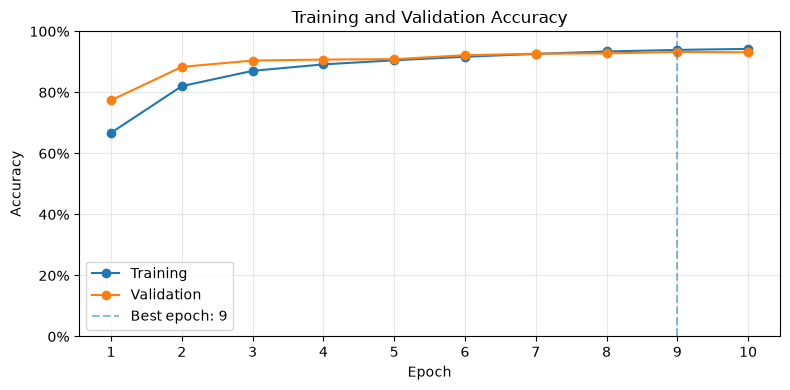

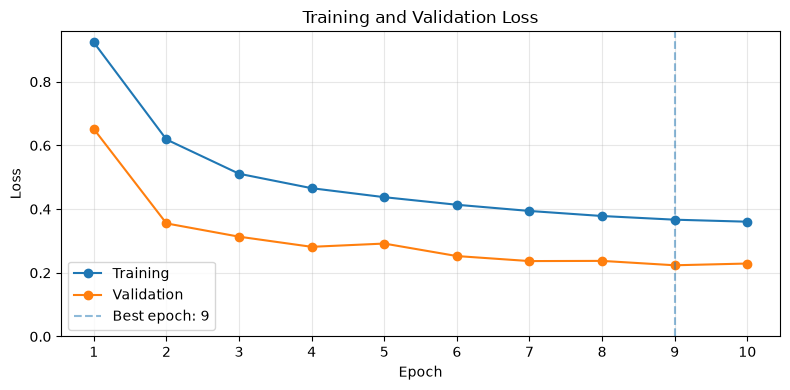

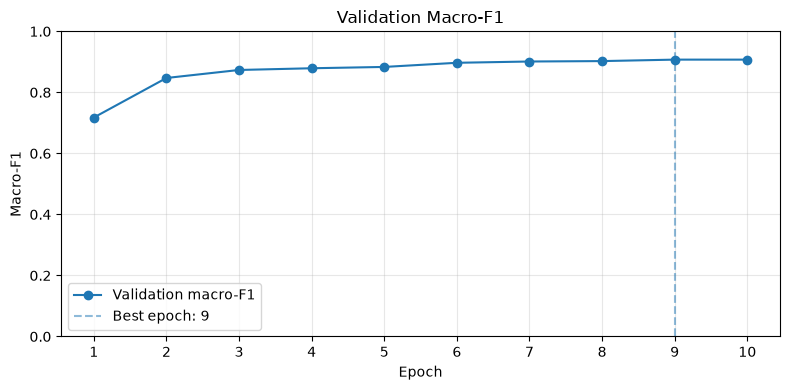

Best checkpoint: epoch 9
Best validation macro-F1: 0.9073


In [11]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

run_id = "r50-cbam-full-001"

project_root = next(
    (
        path for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "results" / "runs" / run_id / "history.csv").is_file()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(f"Could not find history.csv for {run_id}")

history = pd.read_csv(
    project_root / "results" / "runs" / run_id / "history.csv"
)

epochs = history["epoch"]
best_epoch = int(
    history.loc[history["validation_macro_f1"].idxmax(), "epoch"]
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(epochs, history["train_accuracy"], marker="o", label="Training")
ax.plot(epochs, history["validation_accuracy"], marker="o", label="Validation")
ax.axvline(best_epoch, linestyle="--", alpha=0.5, label=f"Best epoch: {best_epoch}")

ax.set(
    title="Training and Validation Accuracy",
    xlabel="Epoch",
    ylabel="Accuracy",
    ylim=(0, 1),
)
ax.set_xticks(epochs)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(epochs, history["train_loss"], marker="o", label="Training")
ax.plot(epochs, history["validation_loss"], marker="o", label="Validation")
ax.axvline(best_epoch, linestyle="--", alpha=0.5, label=f"Best epoch: {best_epoch}")

ax.set(
    title="Training and Validation Loss",
    xlabel="Epoch",
    ylabel="Loss",
)
ax.set_xticks(epochs)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    epochs,
    history["validation_macro_f1"],
    marker="o",
    label="Validation macro-F1",
)
ax.axvline(best_epoch, linestyle="--", alpha=0.5, label=f"Best epoch: {best_epoch}")

ax.set(
    title="Validation Macro-F1",
    xlabel="Epoch",
    ylabel="Macro-F1",
    ylim=(0, 1),
)
ax.set_xticks(epochs)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

print(f"Best checkpoint: epoch {best_epoch}")
print(f"Best validation macro-F1: {history['validation_macro_f1'].max():.4f}")